In [4]:
# Kendi çalışma notu: Sonuç tablosunda sınıf dağılımını da kontrol et.
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,roc_auc_score,accuracy_score

In [5]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

#### veriyi okuyalım

In [6]:
column_names = ["age","sex","cp","trestbps","chol","fbs","restecg",
                "thalach","exang","oldpeak","slope","ca","thal","target"]
df = pd.read_csv("/content/processed.cleveland.data",header=None,names=column_names,na_values="?")
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


#### eksikleri atalım, hedefi 0/1 yapalım, one hot encoding

In [7]:
df = df.dropna()
df["disease"] = (df["target"]>0).astype(int)
df = df.drop(columns=["target"])
df = pd.get_dummies(df,columns=["cp","restecg","slope","thal"],drop_first=True,dtype=int)

X = df.drop(columns=["disease"])
y = df["disease"]

print("X:", X.shape)
print("y:", y.shape)
print(y.value_counts())

X: (297, 18)
y: (297,)
disease
0    160
1    137
Name: count, dtype: int64


#### train, validation, test

In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=SEED,stratify=y)
X_train,X_val,y_train,y_val = train_test_split(X_train,y_train,test_size=0.20,random_state=SEED,stratify=y_train)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (189, 18)
Validation: (48, 18)
Test: (60, 18)


#### scale edelim

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

#### modeli kuralım

In [10]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16,activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(8,activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1,activation="sigmoid")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 449 (1.75 KB)

 Trainable params: 449 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")]
)

In [12]:
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss",patience=15,restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=5,min_lr=0.00001)

#### eğitelim

In [13]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val,y_val),
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping,reduce_lr],
    verbose=1
)
print("Durduğu epoch:", len(history.history["loss"]))

Epoch 1/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.4233 - loss: 0.8655 - val_accuracy: 0.4375 - val_loss: 0.7646 - learning_rate: 0.0010
Epoch 2/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4921 - loss: 0.7927 - val_accuracy: 0.5000 - val_loss: 0.7343 - learning_rate: 0.0010
Epoch 3/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4656 - loss: 0.8012 - val_accuracy: 0.5625 - val_loss: 0.7124 - learning_rate: 0.0010
Epoch 4/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5185 - loss: 0.7248 - val_accuracy: 0.5417 - val_loss: 0.6987 - learning_rate: 0.0010
Epoch 5/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5132 - loss: 0.7027 - val_accuracy: 0.5833 - val_loss: 0.6857 - learning_rate: 0.0010
Epoch 6/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5132 - loss: 0.7166 - val_accuracy: 0.6042 - val_loss: 0.6747 - learning_rate: 0.0010
Epoch 7/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5926 - loss: 0.6629 - 

#### test edelim

In [14]:
test_loss,test_accuracy = model.evaluate(X_test,y_test,verbose=0)
print("Test Loss:", round(test_loss,4))
print("Test Accuracy:", round(test_accuracy,4))

Test Loss: 0.3227
Test Accuracy: 0.8333


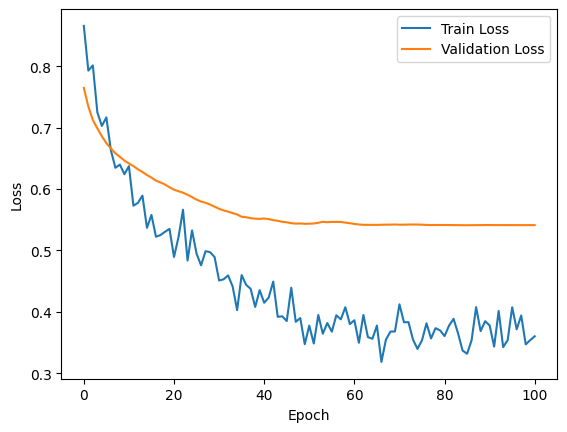

In [15]:
plt.plot(history.history["loss"],label="Train Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

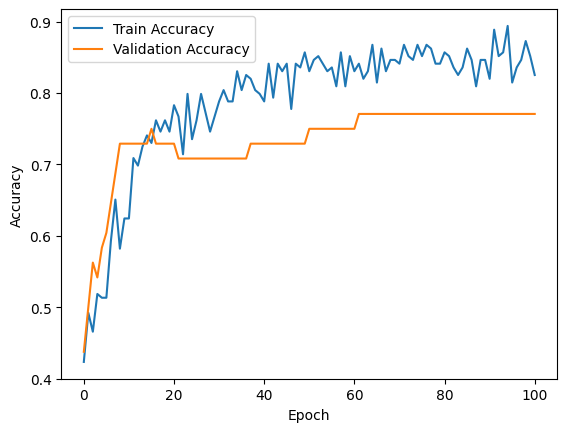

In [16]:
plt.plot(history.history["accuracy"],label="Train Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [17]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob>=0.5).astype(int)
print(y_pred[:10])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
[0 0 1 0 0 0 0 0 0 0]


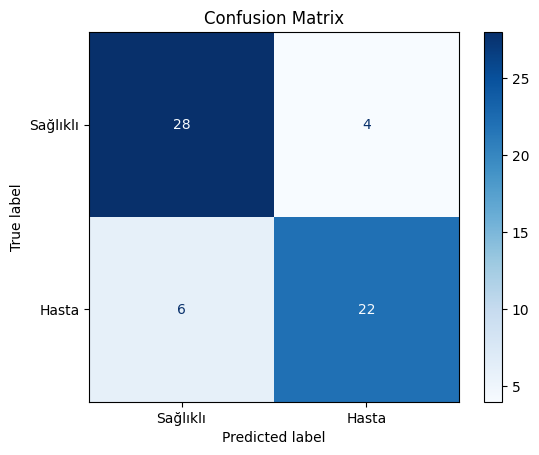

In [18]:
cm = confusion_matrix(y_test,y_pred)
ConfusionMatrixDisplay(cm,display_labels=["Sağlıklı","Hasta"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [19]:
print(classification_report(y_test,y_pred,target_names=["Sağlıklı","Hasta"]))
print("ROC-AUC:", round(roc_auc_score(y_test,y_prob),4))

              precision    recall  f1-score   support

    Sağlıklı       0.82      0.88      0.85        32
       Hasta       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60

ROC-AUC: 0.9375


#### logistic regresyonla karşılaştıralım

In [20]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train,y_train)
lr_prob = log_reg.predict_proba(X_test)[:,1]

pd.DataFrame({
    "Accuracy": [accuracy_score(y_test,y_pred),accuracy_score(y_test,(lr_prob>=0.5).astype(int))],
    "ROC-AUC": [roc_auc_score(y_test,y_prob),roc_auc_score(y_test,lr_prob)],
},index=["Keras ANN","Logistic Regression"])

,Accuracy,ROC-AUC
Keras ANN,0.833333,0.937500
Logistic Regression,0.833333,0.950893


### Çalışma değerlendirmesi

Olasılık eşiği değiştiğinde accuracy ve ROC-AUC farklı davranır; ROC-AUC eşikten bağımsızdır.
